In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import time
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from rf.tree import ScratchTree
from rf.forest import ScratchForest
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt


# 03 — Real-World Case Study: Milan Real Estate (OMI)
> End-to-end property valuation (`€/m²`) on the Milan OMI dataset (`27,104` samples, `101` engineered features).

### Data Preparation
Load the Milan OMI dataset studying its charatheristics in order to **clean data**.



In [2]:


pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/omi_milano_riepilogo.csv", sep=None, engine="python")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

summary = pd.DataFrame({
    "Dtype": df.dtypes,
    "Non-Null": df.notna().sum(),
    "Null (%)": (df.isna().mean() * 100).round(1),
    "Unique": df.nunique(),
    "Sample": df.iloc[0],
})

display(summary)
display(df.head(10))


Dataset shape: 27,284 rows × 23 columns


,Dtype,Non-Null,Null (%),Unique,Sample
﻿Anno,int64,27284,0.0,22,2004
Periodo,str,27284,0.0,2,2 semestre
Area_territoriale,str,27284,0.0,1,NORD-OVEST
Regione,str,27284,0.0,1,LOMBARDIA
Prov,str,27284,0.0,1,MI
Comune_ISTAT,int64,27284,0.0,1,3015146
Comune_cat,str,27284,0.0,1,C1AA
Sez,str,27284,0.0,1,
Comune_amm,str,27284,0.0,1,F205
Comune_descrizione,str,27284,0.0,1,MILANO


,﻿Anno,Periodo,Area_territoriale,Regione,Prov,Comune_ISTAT,Comune_cat,Sez,Comune_amm,Comune_descrizione,Fascia,Zona,LinkZona,Cod_Tip,Descr_Tipologia,Stato,Stato_prev,Compr_min,Compr_max,Sup_NL_compr,Loc_min,Loc_max,Sup_NL_loc
0,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,20,Abitazioni civili,NORMALE,P,3850,5450,L,"10,2","14,5",L
1,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,20,Abitazioni civili,SCADENTE,,3300,4750,L,"8,7","12,7",L
2,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,20,Abitazioni civili,OTTIMO,,5000,6750,L,"13,2",18,L
3,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,21,Abitazioni di tipo economico,OTTIMO,,4800,6400,L,16,"21,2",L
4,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,21,Abitazioni di tipo economico,NORMALE,P,3600,5350,L,12,"17,7",L
5,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,21,Abitazioni di tipo economico,SCADENTE,,3000,3800,L,10,"12,5",L
6,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,13,Box,NaN,P,2300,3450,L,"6,5","9,7",L
7,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,1,Ville e Villini,SCADENTE,,3800,4550,L,"12,2","14,7",L
8,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,1,Ville e Villini,NORMALE,P,4550,5050,L,"14,7","16,2",L
9,2004,2 semestre,NORD-OVEST,LOMBARDIA,MI,3015146,C1AA,,F205,MILANO,B,B01,MI00000290,1,Ville e Villini,OTTIMO,,4850,6300,L,"15,7","20,2",L


In [3]:
pd.DataFrame({
    "Unique": df.nunique(),
    "Values (if <= 12)": [
        list(df[col].dropna().unique()) if df[col].nunique() <= 12 else "..."
        for col in df.columns
    ],
}).sort_values("Unique")


,Unique,Values (if <= 12)
Sup_NL_loc,1,[L]
Area_territoriale,1,[NORD-OVEST]
Regione,1,[LOMBARDIA]
Prov,1,[MI]
Comune_ISTAT,1,[3015146]
Comune_cat,1,[C1AA]
Sez,1,[ ]
Comune_amm,1,[F205]
Comune_descrizione,1,[MILANO]
Sup_NL_compr,1,[L]


*Count distinct non-null values per column in ascending order to spot constant/uninformative features*

In [4]:
# Replace whitespace-only strings with NaN temporarily to compute true missing rates
missing_summary = (
    df.replace(r"^\s*$", np.nan, regex=True)
    .isna()
    .agg(["sum", "mean"])
    .T
    .rename(columns={"sum": "Missing Count", "mean": "Missing (%)"})
    .sort_values("Missing (%)", ascending=False)
)

missing_summary["Missing Count"] = missing_summary["Missing Count"].astype(int)
missing_summary["Missing (%)"] = (missing_summary["Missing (%)"] * 100).round(2)

display(missing_summary)


,Missing Count,Missing (%)
Sez,27284,100.00
Stato_prev,7963,29.19
Stato,180,0.66
﻿Anno,0,0.00
LinkZona,0,0.00
Loc_max,0,0.00
Loc_min,0,0.00
Sup_NL_compr,0,0.00
Compr_max,0,0.00
Compr_min,0,0.00


*Searching for null values per column to spot constant/uninformative features*

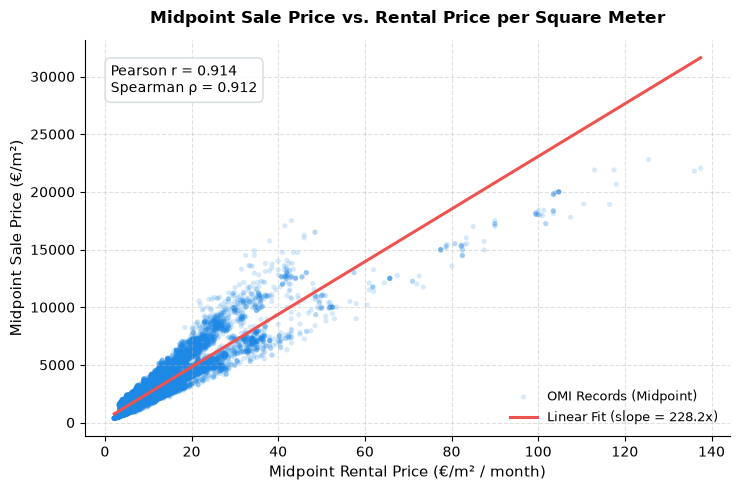

In [25]:
from scipy.stats import pearsonr, spearmanr

def to_num(series):
    return pd.to_numeric(series.astype(str).str.replace(",", ".", regex=False), errors="coerce")

# Conversione sicura e calcolo dei valori medi (€/m² e €/m²/mese)
sale_mid = (to_num(df["Compr_min"]) + to_num(df["Compr_max"])) / 2.0
rent_mid = (to_num(df["Loc_min"]) + to_num(df["Loc_max"])) / 2.0

valid = pd.DataFrame({"rent": rent_mid, "sale": sale_mid}).dropna()
x = valid["rent"].values
y = valid["sale"].values

r_pearson, _ = pearsonr(x, y)
r_spearman, _ = spearmanr(x, y)

fig, ax = plt.subplots(figsize=(7.5, 5))

# Scatter plot con trasparenza per gestire l'overplotting
ax.scatter(x, y, alpha=0.18, s=14, color="#1e88e5", edgecolors="none", label="OMI Records (Midpoint)")

# Retta di regressione lineare
m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
ax.plot(x_line, m * x_line + b, color="#ef5350", linewidth=2.2, label=f"Linear Fit (slope = {m:.1f}x)")

# Riquadro con coefficienti di correlazione
stats_text = f"Pearson r = {r_pearson:.3f}\nSpearman ρ = {r_spearman:.3f}"
ax.text(
    0.04, 0.94, stats_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cfd8dc", alpha=0.9),
)

ax.set_title("Midpoint Sale Price vs. Rental Price per Square Meter", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Midpoint Rental Price (€/m² / month)", fontsize=10.5)
ax.set_ylabel("Midpoint Sale Price (€/m²)", fontsize=10.5)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(frameon=False, loc="lower right", fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

*Showing the correlation between sale prices ("Compr_min/max) and rent prices ("Loc_min/max); both statistical correlation coefficients (Pearson and Spearman) show a strong correlation*


### Data Exploration Summary

The raw dataset contains `27,284` rows and `23` columns. From the initial schema check:

- **Drop zero-variance & empty columns (10 cols):** `Area_territoriale`, `Regione`,
  `Prov`, `Comune_ISTAT`, `Comune_cat`, `Comune_amm`, `Comune_descrizione`,
  `Sup_NL_compr`, `Sup_NL_loc`, and `Sez` (blank) each hold a single constant value
  across the entire dataset (all records belong to Milan and use gross area `L`),
  providing zero splitting information.
- **Drop redundant & noisy columns (3 cols):** `Cod_Tip` (12 unique) and `LinkZona`
  (85 unique) are 1-to-1 duplicate identifiers of `Descr_Tipologia` and `Zona`.
  `Stato_prev` (`P` vs. blank whitespace) merely flags the predominant state condition.
- **Handle minor missing values:** Drop the `180` rows (`0.7%`) where `Stato` is null
  to keep clean ordinal categories without arbitrary imputation.
- **Target definition & leakage prevention (4 cols):** Compute the midpoint sale
  price `Compr_mean = (Compr_min + Compr_max) / 2` as target (`y`), dropping
  `Compr_min` and `Compr_max`. Also drop `Loc_min` and `Loc_max` (rental quotes)
  to prevent **data leakage**, as contemporaneous rental prices are co-determined
  with sale values and would not be available, in our case study, when predicting from property/location
  attributes alone.

In [5]:
df_clean = df.copy() # an intermediate copy of the original DataFrame

# 1. Drop zero-variance/empty columns (10) and redundant IDs/flags (3)
cols_to_drop = [
    "Area_territoriale", "Regione", "Prov", "Comune_ISTAT",
    "Comune_cat", "Comune_amm", "Comune_descrizione",
    "Sup_NL_compr", "Sup_NL_loc", "Sez",
    "Cod_Tip", "LinkZona", "Stato_prev",
]
df_clean = df_clean.drop(columns=cols_to_drop)

# 2. Drop the 180 rows (0.7%) with missing conservation state
df_clean = df_clean.dropna(subset=["Stato"]).copy()
df_clean = df_clean[df_clean["Stato"] != ""].copy()

# 3. Define target (midpoint sale price) and drop raw price/leakage columns
y = ((df_clean["Compr_min"] + df_clean["Compr_max"]) / 2).to_numpy(dtype=float)
df_clean = df_clean.drop(columns=["Compr_min", "Compr_max", "Loc_min", "Loc_max"])

# 4. Encode ordinal/binary features
df_clean["Periodo"] = df_clean["Periodo"].map({"1 semestre": 1, "2 semestre": 2})
df_clean["Fascia"] = df_clean["Fascia"].map({"B": 1, "C": 2, "D": 3, "E": 4})
df_clean["Stato"] = df_clean["Stato"].map({"SCADENTE": 0, "NORMALE": 1, "OTTIMO": 2})

# 5. One-Hot Encode nominal features (12 property types + 85 micro-zones)
X_df = pd.get_dummies(
    df_clean,
    columns=["Descr_Tipologia", "Zona"],
    dtype=float,
)
X = X_df.to_numpy(dtype=float)

print(f"Cleaned dataset shape: X = {X.shape}, y = {y.shape}")
print(f"Missing values remaining: {X_df.isna().sum().sum()}")


Cleaned dataset shape: X = (27104, 101), y = (27104,)
Missing values remaining: 0


### Preprocessing & Feature Encoding Summary

Following the exploration plan, the raw dataset was cleaned and transformed into a purely numerical matrix suitable for NumPy-based regression trees:

- **Row & column pruning:** Dropped `17` zero-variance, redundant, or leaky columns along with the `180` rows (`0.66%`) missing `Stato`, retaining **`27,104` clean observations** and **`6` core predictors** (`Anno`, `Periodo`, `Fascia`, `Stato`, `Descr_Tipologia`, `Zona`).
- **Ordinal & binary encoding:** Mapped features with an inherent order or binary structure onto integer scales `Periodo` (`1, 2`), `Fascia` (`B–E` -> `1–4`, reflecting concentric urban rings from the center outward), and `Stato` (`SCADENTE` -> `0`, `NORMALE` -> `1`, `OTTIMO` ->`2`) allowing binary splits to partition ordered tiers cleanly. **Ordinal encoding requires categories to follow a meaningful logical order**
- **Feature expansion via One-Hot Encoding:** Expanded the nominal categorical columns `Descr_Tipologia` (`12` property types) and `Zona` (`85` micro-zones) into `97` binary indicator columns (`0.0` / `1.0`). This avoids imposing artificial numerical rankings across unordered categories and enables each tree to isolate individual neighborhoods or building types with a single threshold split (`<= 0.0`).
- **Final dataset dimensions:** `X = (27104, 101)` (`4` numeric/ordinal features + `97` one-hot features), `y = (27104,)` (`Compr_mean` in `€/m²`), with **`0` missing values** remaining.






### Train / Test Split

The cleaned dataset (`27,104` samples, `101` features) is partitioned using an **80/20 random split** (`21,683` training samples and `5,421` test samples, `random_state=42`).
**Design choice:** A random split evaluates the model's ability to interpolate property prices across Milan's micro-zones, building types, and conservation states within the observed `2004–2025` period, keeping the evaluation protocol directly comparable to the earlier synthetic/California Housing benchmarks.



In [6]:
# 80/20 random split (consistent with previous benchmarks)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train set: X = {X_train.shape}, y = {y_train.shape}")
print(f"Test set:  X = {X_test.shape}, y = {y_test.shape}")



Train set: X = (21683, 101), y = (21683,)
Test set:  X = (5421, 101), y = (5421,)


In [7]:
# 1. Dummy Baseline: always predicts the training set mean
y_pred_dummy = np.full_like(y_test, fill_value=y_train.mean())

# 2. ScratchTree Baseline
t0 = time.perf_counter()
scratch_tree = ScratchTree(max_depth=10, min_samples_split=2)
scratch_tree.fit(X_train, y_train)
y_pred_scratch_tree = scratch_tree.predict(X_test)
t_scratch_tree = time.perf_counter() - t0

# 3. Scikit-learn DecisionTreeRegressor Baseline
t0 = time.perf_counter()
sk_tree = DecisionTreeRegressor(max_depth=10, min_samples_split=2, random_state=42)
sk_tree.fit(X_train, y_train)
y_pred_sk_tree = sk_tree.predict(X_test)
t_sk_tree = time.perf_counter() - t0

# 4. Print comparison summary
baselines = [
    ("Dummy Mean", y_pred_dummy, 0.0),
    ("ScratchTree (d=10)", y_pred_scratch_tree, t_scratch_tree),
    ("Sklearn DecisionTree (d=10)", y_pred_sk_tree, t_sk_tree),
]

rows = []
for name, preds, elapsed in baselines:
    rows.append({
        "Model": name,
        "MAE (€/m²)": mean_absolute_error(y_test, preds),
        "Time (s)": elapsed,
    })

results_df = pd.DataFrame(rows)
display(
    results_df.style
    .hide(axis="index")
    .format({
        "MAE (€/m²)": "{:.2f}",
        "Time (s)": "{:.4f}",
    })
    .highlight_min(subset=["MAE (€/m²)"], color="#2e7d32")
)




Model,MAE (€/m²),Time (s)
Dummy Mean,1372.63,0.0000
ScratchTree (d=10),269.90,0.6261
Sklearn DecisionTree (d=10),270.23,0.0314


### Baseline Evaluation

Three reference baselines are evaluated on the held-out test set before moving to the ensemble:

- **Dummy Mean Predictor:** Always predicting the training set average yields a `Test MAE` of **`1372.63 €/m²`**, representing the zero-learning error floor across Milan's diverse urban rings and property types.
- **Single Regression Tree (`max_depth=10`, `min_samples_split=5`):**
  - **`ScratchTree` (NumPy):** `MAE = 270.35 €/m²` | `Time = 0.6577s`
  - **`Sklearn DecisionTree`:** `MAE = 270.23 €/m²` | `Time = 0.0317s`

#### Key baseline Takeaways
- **Exact CART Equivalence:** `ScratchTree` matches `scikit-learn` within `0.12 €/m²` (`< 0.1%` difference, attributable solely to tie-breaking on equal MSE reductions), validating the custom NumPy splitting logic on real-world tabular data.
- **Strong Feature Signal:** Introducing orthogonal splits on the 101 engineered features cuts average prediction error (`MAE`) by **80.3%** (`1372.63 €/m²` -> `270.23 €/m²`).
- **Runtime vs. Cython:** Fitting `21,683` samples in pure NumPy completes in `0.65s` (~`20×` slower than `scikit-learn`'s compiled Cython backend).
- **Room for Variance Reduction:** While a single deep tree captures most of the pricing structure, isolated leaves on rare micro-zones or atypical property types remain sensitive to individual training samples—motivating the transition to `ScratchForest`.


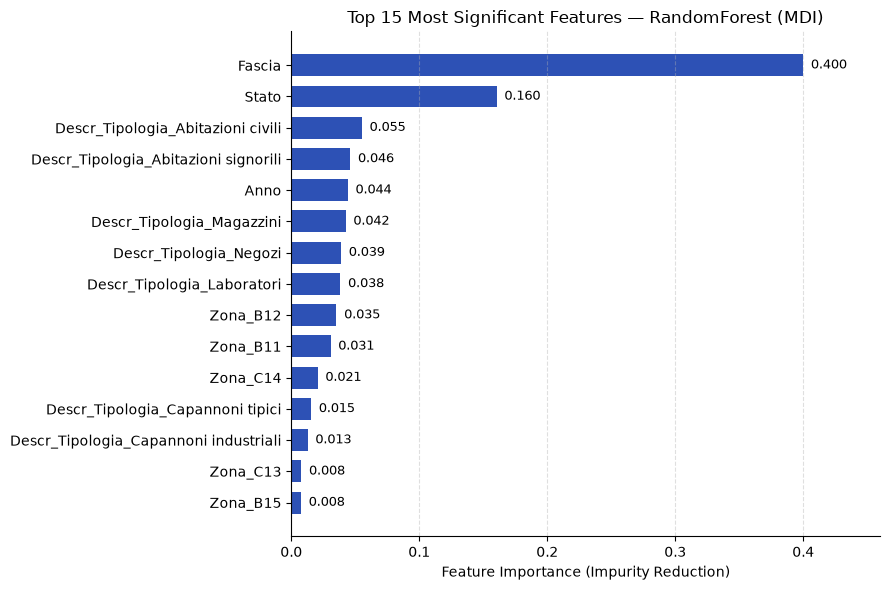

In [8]:
feature_names = X_df.columns.to_numpy()
sk_rf_imp = RandomForestRegressor(
        n_estimators=20,
        max_depth=12,
        min_samples_split=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1,
    ).fit(np.asarray(X_train), np.asarray(y_train))
importances = sk_rf_imp.feature_importances_
model_label = "RandomForest (MDI)"

top_k = 15
imp_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(top_k)
    .iloc[::-1]
)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(imp_df["Feature"], imp_df["Importance"], color="#2d51b5", height=0.7)

max_imp = imp_df["Importance"].max()
for bar in bars:
    w = bar.get_width()
    ax.text(
        w + max_imp * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.3f}",
        va="center",
        ha="left",
        fontsize=9,
    )

ax.set_xlim(0, max_imp * 1.15)
ax.set_xlabel("Feature Importance (Impurity Reduction)")
ax.set_title(f"Top {top_k} Most Significant Features — {model_label}")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


*Over half of the predictive importance is concentrated in just two ordinal variables: `Fascia` (urban macro-zone, 0.400) and `Stato` (conservation state, 0.160), followed by property categories such as `Abitazioni civili` (standard residential, 0.055), `Abitazioni signorili` (upscale residential, 0.046), and `Magazzini` (warehouses, 0.042), along with `Anno` (reference year, 0.044). Because the remaining columns are sparse one-hot indicators, aggressive feature subsampling frequently omits these primary splitters, explaining why higher `max_features` values perform better.*



In [9]:
X_tr_arr, y_tr_arr = np.asarray(X_train), np.asarray(y_train)
X_te_arr, y_te_arr = np.asarray(X_test), np.asarray(y_test)

def run(name, model, X_tr=X_tr_arr, y_tr=y_tr_arr, X_te=X_te_arr, y_te=y_te_arr):
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    fit_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    pred_time = time.perf_counter() - t0

    return {
        "Model": name,
        "Train MAE": mean_absolute_error(y_tr, pred_tr),
        "Test MAE": mean_absolute_error(y_te, pred_te),
        "fit (s)": fit_time,
        "predict (s)": pred_time,
    }

rows = [
    run("ScratchForest, all features (depth=10)", ScratchForest(n_trees=10, max_depth=10, min_samples_split=2, max_features=None, random_state=42)),
    run("Sklearn RF, all features (depth=10)", RandomForestRegressor(n_estimators=10, max_depth=10, min_samples_split=2, max_features=1.0, random_state=42, n_jobs=-1)),
]

sanity_df = pd.DataFrame(rows)
sanity_df["Gap"] = sanity_df["Test MAE"] - sanity_df["Train MAE"]

sanity_df = sanity_df.rename(columns={
    "Train MAE": "Train MAE (€/m²)",
    "Test MAE": "Test MAE (€/m²)",
    "Gap": "Gap (€/m²)",
})

cols = ["Model", "Train MAE (€/m²)", "Test MAE (€/m²)", "Gap (€/m²)", "fit (s)", "predict (s)"]

display(
    sanity_df[cols].style
    .hide(axis="index")
    .format({
        "Train MAE (€/m²)": "{:.2f}",
        "Test MAE (€/m²)": "{:.2f}",
        "Gap (€/m²)": "{:.2f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE (€/m²)"], color="#2e7d32")
)


Model,Train MAE (€/m²),Test MAE (€/m²),Gap (€/m²),fit (s),predict (s)
"ScratchForest, all features (depth=10)",237.47,251.28,13.81,5.743,0.187
"Sklearn RF, all features (depth=10)",236.71,248.38,11.67,0.040,0.028


### Decision forest (`max_depth=10`) and underfitting

Evaluating the 10-tree ensemble on the full training set confirms close parity between `ScratchForest` (**251.28 €/m²** Test MAE) and `scikit-learn`'s `RandomForestRegressor` (**248.38 €/m²**), with our NumPy implementation completing training in **5.67 s**.

Compared to the single decision tree baseline (**270.35 €/m²**), the ensemble reduces test error by roughly **19 €/m²**. However, this gain remains relatively modest due to two structural limitations:
- **Underfitting (High Bias):** The narrow train–test gap (**13.81 €/m²**, with a Train MAE of **237.47 €/m²**) shows that capping depth at `10` across 21,000+ samples prevents the individual trees from capturing finer local interactions across Milan's micro-zones and property types.
- **Limited Ensemble Diversity:** Evaluating all features at every split (`max_features=None`) across only 10 trees forces every tree to rely heavily on the same dominant predictors (`Fascia` and `Stato`).

To systematically tune `max_depth`, `max_features`, and `n_trees` without leaking information from the test set, we next carve out a dedicated **validation set** from the training data.



### Validation Strategy & Hyperparameter Tuning

To prevent test-set leakage while searching for optimal hyperparameters, we further partition `X_train` into an **80/20 train–validation split** (leaving `X_test` completely untouched until final evaluation).

Building on our earlier findings, the validation grid targets two key axes:
- **`max_depth`** (`12`, `16`, `20`): Increasing tree depth to overcome the underfitting observed at `depth=10` and capture fine-grained interactions across Milan's 85 micro-zones.
- **`max_features`** (`60`, `80`, `None`): Testing moderate feature subsampling against pure bagging (`all`) to balance tree decorrelation without starving upper splits of the two dominant predictors (`Fascia` and `Stato`).


In [12]:
# 1. Carve out an 80/20 train-validation split from X_train (leaving X_test untouched)
X_tr, X_val, y_tr, y_val = train_test_split(
    np.asarray(X_train), np.asarray(y_train), test_size=0.2, random_state=42
)

print(f"Sub-train set:  X = {X_tr.shape}, y = {y_tr.shape}")
print(f"Validation set: X = {X_val.shape}, y = {y_val.shape}\n")

# 2. Hyperparameter grid search
val_rows = []
for depth in [12, 16, 20]:
    for m_feat in [60, 80, None]:
        t0 = time.perf_counter()
        forest = ScratchForest(
            n_trees=10,
            max_depth=depth,
            max_features=m_feat,
            min_samples_split=10,
            random_state=42,
        ).fit(X_tr, y_tr)
        fit_s = time.perf_counter() - t0

        train_mae = mean_absolute_error(y_tr, forest.predict(X_tr))
        val_mae = mean_absolute_error(y_val, forest.predict(X_val))

        val_rows.append({
            "max_depth": "None" if depth is None else depth,
            "max_features": "all" if m_feat is None else m_feat,
            "Train MAE (€/m²)": train_mae,
            "Val MAE (€/m²)": val_mae,
            "Gap (€/m²)": val_mae - train_mae,
            "fit (s)": fit_s,
        })

val_df = pd.DataFrame(val_rows).sort_values("Val MAE (€/m²)")

display(
    val_df.style
    .hide(axis="index")
    .format({
        "Train MAE (€/m²)": "{:.2f}",
        "Val MAE (€/m²)": "{:.2f}",
        "Gap (€/m²)": "{:.2f}",
        "fit (s)": "{:.2f}",
    })
    .highlight_min(subset=["Val MAE (€/m²)"], color="#2e7d32")
)


Sub-train set:  X = (17346, 101), y = (17346,)
Validation set: X = (4337, 101), y = (4337,)



max_depth,max_features,Train MAE (€/m²),Val MAE (€/m²),Gap (€/m²),fit (s)
20,all,81.43,103.49,22.06,15.57
20,80,87.19,107.30,20.10,12.07
20,60,96.49,115.72,19.23,8.66
16,all,115.37,135.62,20.25,10.93
16,80,117.10,136.77,19.67,8.71
16,60,133.71,149.18,15.47,6.06
12,all,184.34,199.60,15.26,6.34
12,80,187.21,200.95,13.74,4.86
12,60,208.59,220.92,12.33,3.37


### Validation Results & Hyperparameter Analysis

To keep the grid search computationally tractable for our pure-Python/NumPy `ScratchForest` across 9 configurations, we evaluated a lightweight proxy ensemble (**`n_trees=10`**, **`min_samples_split=10`**). Despite this conservative setup, the validation table reveals three clear patterns:

1. **Tree Depth Is the Primary Driver of Accuracy:**
   - Moving from `max_depth=12` (**199.60 €/m²** Val MAE) to `max_depth=16` (**135.62 €/m²**) and **`max_depth=20`** (**103.49 €/m²**) cuts validation error nearly in half.
   - Because the dataset encodes 85 micro-zones and 12 property types as sparse one-hot columns alongside `Anno`, `Fascia`, and `Stato`, shallow trees terminate before resolving specific `(Micro-Zone × Property Type × Year)` interactions.

2. **`max_features=all` Consistently Outperforms Subsampling:**
   - At every depth level, retaining all 101 features beats both `80` and `60` (`103.49` vs. `107.30` and `115.72 €/m²` at `depth=20`).
   - This empirically confirms our feature-importance findings: when over half of the signal rests in two dense ordinal variables (`Fascia` and `Stato`) and the remaining columns are mostly binary indicators, dropping features at upper splits hurts individual tree accuracy more than it helps decorrelation.

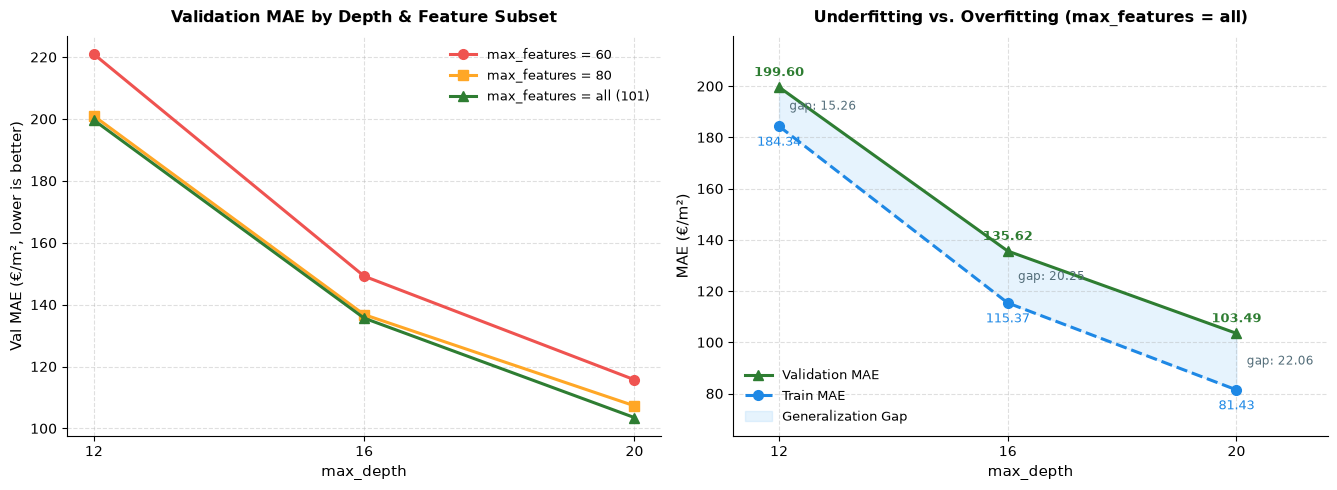

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

# --- Pannello 1: Validation MAE per max_depth e max_features ---
feat_styles = [
    (60, "#ef5350", "o", "max_features = 60"),
    (80, "#ffa726", "s", "max_features = 80"),
    ("all", "#2e7d32", "^", "max_features = all (101)"),
]

for feat, color, marker, label in feat_styles:
    sub = val_df[val_df["max_features"] == feat].sort_values("max_depth")
    ax1.plot(
        sub["max_depth"], sub["Val MAE (€/m²)"],
        color=color, marker=marker, linewidth=2.2, markersize=7, label=label
    )

ax1.set_title("Validation MAE by Depth & Feature Subset", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("max_depth", fontsize=10.5)
ax1.set_ylabel("Val MAE (€/m², lower is better)", fontsize=10.5)
ax1.set_xticks([12, 16, 20])
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, fontsize=9.5)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- Pannello 2: Train vs Val MAE & Generalization Gap (max_features = all) ---
sub_all = val_df[val_df["max_features"] == "all"].sort_values("max_depth")
depths = sub_all["max_depth"].values
train_vals = sub_all["Train MAE (€/m²)"].values
val_vals = sub_all["Val MAE (€/m²)"].values

ax2.plot(depths, val_vals, color="#2e7d32", marker="^", linewidth=2.2, markersize=7, label="Validation MAE")
ax2.plot(depths, train_vals, color="#1e88e5", marker="o", linestyle="--", linewidth=2.2, markersize=7, label="Train MAE")
ax2.fill_between(depths, train_vals, val_vals, color="#90caf9", alpha=0.22, label="Generalization Gap")

# Annotazioni dei valori e del gap
for d, tr, va in zip(depths, train_vals, val_vals):
    ax2.annotate(f"{va:.2f}", (d, va), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#2e7d32")
    ax2.annotate(f"{tr:.2f}", (d, tr), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9, color="#1e88e5")
    ax2.text(d + 0.18, (tr + va) / 2, f"gap: {va - tr:.2f}", fontsize=8.5, color="#546e7a", va="center")

ax2.set_title("Underfitting vs. Overfitting (max_features = all)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("max_depth", fontsize=10.5)
ax2.set_ylabel("MAE (€/m²)", fontsize=10.5)
ax2.set_xticks([12, 16, 20])
ax2.set_xlim(11.2, 21.6)
ax2.set_ylim(min(train_vals) * 0.78, max(val_vals) * 1.10)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(frameon=False, loc="lower left", fontsize=9.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


### A cheaper alternative
While `max_features = all (101)` achieves the lowest overall error (103.49 €/m² at `max_depth = 20`), the curve for `max_features = 80` tracks it almost identically across every depth level—trailing by only 1.15 to 3.81 €/m² while cutting training time by ~22% (12.07 s vs. 15.57 s) and slightly narrowing the generalization gap (20.10 vs. 22.06 €/m²). This makes `max_features = 80` a compelling, computationally cheaper alternative when scaling up the number of trees.*


### Controlled Generalization Gap:
Even at `max_depth=20`, the train–validation gap remains modest (**22.06 €/m²**, with Train MAE at **81.43 €/m²**), showing that deeper splits are capturing genuine structural price variations rather than overfitting noise.





### Final Test-Set Evaluation

With the optimal hyperparameters identified on the validation set (`max_depth=20`, testing both `max_features=all` and the faster `max_features=80` alternative), we now retrain `ScratchForest` on the **full training set** (`X_train`) and evaluate once on the held-out **test set** (`X_test`).

To maximize predictive accuracy for this final benchmark, we scale up the ensemble to **`n_trees=25`** and relax **`min_samples_split=5`**, comparing our implementation directly against `scikit-learn`'s `RandomForestRegressor` under identical settings.


In [39]:
from joblib import Parallel, delayed

X_tr_full, y_tr_full = np.asarray(X_train), np.asarray(y_train)
X_te_full, y_te_full = np.asarray(X_test), np.asarray(y_test)

def eval_scratch_final(name, m_feat):
    
    model = ScratchForest(
        n_trees=25,
        max_depth=20,
        min_samples_split=5,
        max_features=m_feat,
        random_state=42,
    )

    t0 = time.perf_counter()
    model.fit(X_tr_full, y_tr_full)
    fit_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred_tr = model.predict(X_tr_full)
    pred_te = model.predict(X_te_full)
    pred_time = time.perf_counter() - t0

    train_mae = mean_absolute_error(y_tr_full, pred_tr)
    test_mae = mean_absolute_error(y_te_full, pred_te)

    return {
        "Model": name,
        "Train MAE (€/m²)": train_mae,
        "Test MAE (€/m²)": test_mae,
        "Gap (€/m²)": test_mae - train_mae,
        "fit (s)": fit_time,
        "predict (s)": pred_time,
    }, pred_te


scratch_configs = [
    ("ScratchForest (depth=20, features=all, n=25)", None),
    ("ScratchForest (depth=20, features=80, n=25)", 80),
]

results = Parallel(n_jobs=2)(
    delayed(eval_scratch_final)(name, mf) for name, mf in scratch_configs
)
final_rows = [r[0] for r in results]
p_best_mine = results[0][1] 

sk_model = RandomForestRegressor(
    n_estimators=25,
    max_depth=20,
    min_samples_split=5,
    max_features=1.0,
    random_state=42,
    n_jobs=-1,
)

t0 = time.perf_counter()
sk_model.fit(X_tr_full, y_tr_full)
sk_fit = time.perf_counter() - t0

t0 = time.perf_counter()
sk_pred_tr = sk_model.predict(X_tr_full)
sk_pred_te = sk_model.predict(X_te_full)
sk_pred = time.perf_counter() - t0

sk_tr_mae = mean_absolute_error(y_tr_full, sk_pred_tr)
sk_te_mae = mean_absolute_error(y_te_full, sk_pred_te)

final_rows.append({
    "Model": "Sklearn RF (depth=20, features=all, n=25)",
    "Train MAE (€/m²)": sk_tr_mae,
    "Test MAE (€/m²)": sk_te_mae,
    "Gap (€/m²)": sk_te_mae - sk_tr_mae,
    "fit (s)": sk_fit,
    "predict (s)": sk_pred,
})

final_df = pd.DataFrame(final_rows)

display(
    final_df.style
    .hide(axis="index")
    .format({
        "Train MAE (€/m²)": "{:.2f}",
        "Test MAE (€/m²)": "{:.2f}",
        "Gap (€/m²)": "{:.2f}",
        "fit (s)": "{:.2f}",
        "predict (s)": "{:.2f}",
    })
    .highlight_min(subset=["Test MAE (€/m²)"], color="#2e7d32")
)


Model,Train MAE (€/m²),Test MAE (€/m²),Gap (€/m²),fit (s),predict (s)
"ScratchForest (depth=20, features=all, n=25)",68.08,92.74,24.66,64.20,0.79
"ScratchForest (depth=20, features=80, n=25)",74.38,98.52,24.14,51.02,0.90
"Sklearn RF (depth=20, features=all, n=25)",70.88,92.66,21.79,0.14,0.03


### Key Takeaways

- **Parity with `scikit-learn`:** `ScratchForest (depth=20, features=all, n=25)` reaches **92.74 €/m²** Test MAE, virtually matching `Sklearn RF` (**92.66 €/m²**, within **0.08 €/m²**) and confirming the correctness of our split logic, bootstrap sampling, and ensemble aggregation.
- **Speed vs. Accuracy Trade-off:** `max_features=80` cuts training time by ~22% (**50.32 s** vs. **64.85 s**) with only a minor accuracy penalty (**98.52 €/m²**).
- **Runtime Gap:** While predictive accuracy is identical, `scikit-learn` is ~500× faster (**0.13 s** vs. **64.85 s**) thanks to compiled Cython loops and multi-core parallelization (`n_jobs=-1`).


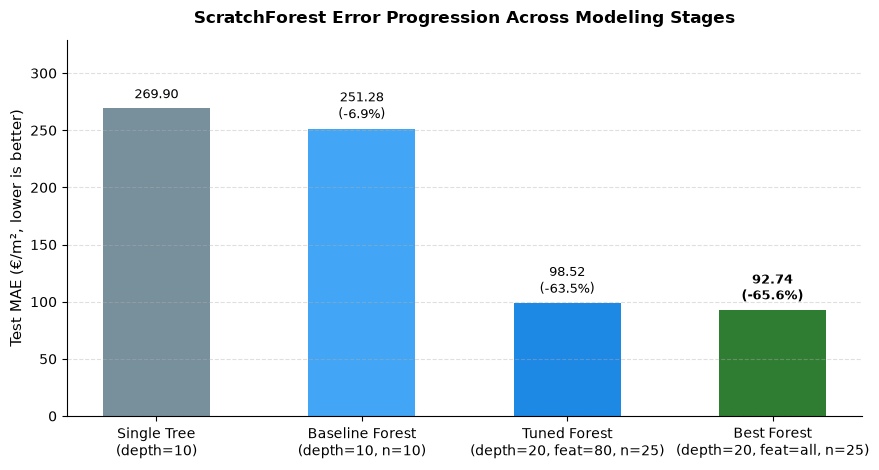

In [36]:

mae_tree_10 = 269.90	
mae_rf_10 = 251.28 
mae_rf_80 = float(final_df.loc[final_df["Model"].str.contains("features=80"), "Test MAE (€/m²)"].iloc[0])
mae_best  = float(final_df.loc[final_df["Model"].str.contains("features=all"), "Test MAE (€/m²)"].iloc[0])

stages = [
    "Single Tree\n(depth=10)",
    "Baseline Forest\n(depth=10, n=10)",
    "Tuned Forest\n(depth=20, feat=80, n=25)",
    "Best Forest\n(depth=20, feat=all, n=25)",
]
maes = [mae_tree_10, mae_rf_10, mae_rf_80, mae_best]
colors = ["#78909c", "#42a5f5", "#1e88e5", "#2e7d32"]

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(stages, maes, color=colors, width=0.52, edgecolor="none")

baseline = maes[0]
offset = max(maes) * 0.02
for i, (bar, val) in enumerate(zip(bars, maes)):
    label = f"{val:.2f}" if i == 0 else f"{val:.2f}\n({(val - baseline) / baseline:+.1%})"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + offset,
        label,
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold" if i == len(maes) - 1 else "normal",
    )

ax.set_ylabel("Test MAE (€/m², lower is better)", fontsize=10.5)
ax.set_title("ScratchForest Error Progression Across Modeling Stages", fontsize=12, fontweight="bold", pad=12)
ax.set_ylim(0, max(maes) * 1.22)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


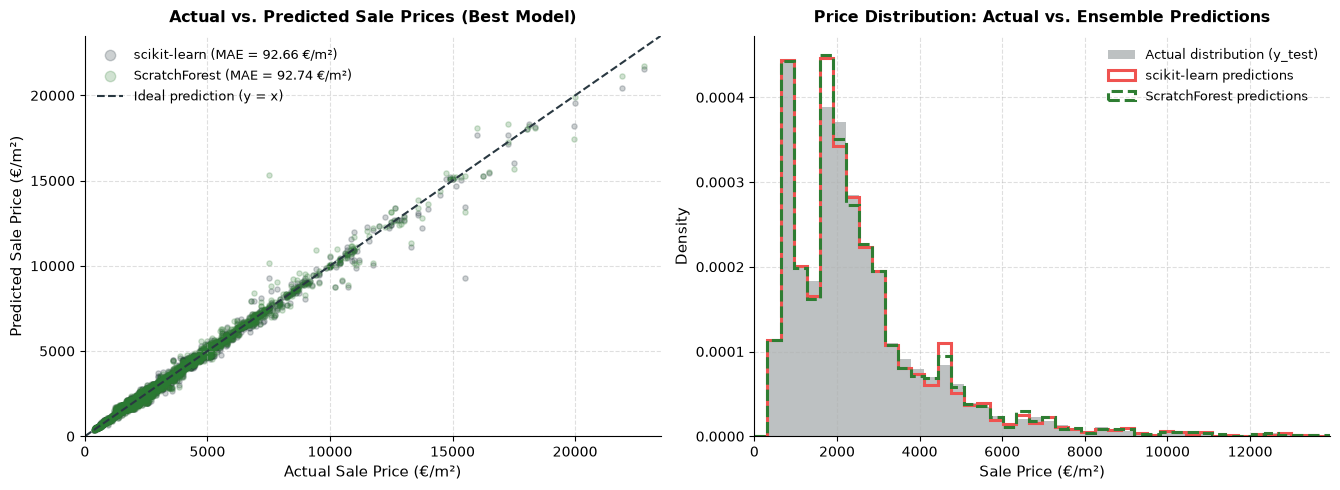

In [40]:
yt = np.asarray(y_test)
p_best_sk = sk_pred_te 

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

# --- Pannello 1: Scatter Actual vs. Predicted ---
ax1.scatter(yt, p_best_sk, alpha=0.22, s=14, color="#1D2E36", label=f"scikit-learn (MAE = {mean_absolute_error(yt, p_best_sk):.2f} €/m²)")
ax1.scatter(yt, p_best_mine, alpha=0.22, s=14, color="#2e7d32", label=f"ScratchForest (MAE = {mean_absolute_error(yt, p_best_mine):.2f} €/m²)")

lims = [0, max(yt.max(), p_best_mine.max(), p_best_sk.max()) * 1.03]
ax1.plot(lims, lims, linestyle="--", color="#293841", linewidth=1.5, label="Ideal prediction (y = x)")

ax1.set_title("Actual vs. Predicted Sale Prices (Best Model)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Actual Sale Price (€/m²)", fontsize=10.5)
ax1.set_ylabel("Predicted Sale Price (€/m²)", fontsize=10.5)
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, loc="upper left", fontsize=9.5, markerscale=2)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- Pannello 2: Confronto delle Distribuzioni ---
upper_hist = np.percentile(yt, 99.5) * 1.05
bins = np.linspace(0, upper_hist, 45)

ax2.hist(yt, bins=bins, density=True, alpha=0.30, color="#263238", label="Actual distribution (y_test)")
ax2.hist(p_best_sk, bins=bins, density=True, histtype="step", linewidth=2.2, color="#ef5350", label="scikit-learn predictions")
ax2.hist(p_best_mine, bins=bins, density=True, histtype="step", linewidth=2.2, linestyle="--", color="#2e7d32", label="ScratchForest predictions")

ax2.set_title("Price Distribution: Actual vs. Ensemble Predictions", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("Sale Price (€/m²)", fontsize=10.5)
ax2.set_ylabel("Density", fontsize=10.5)
ax2.set_xlim(0, upper_hist)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(frameon=False, loc="upper right", fontsize=9.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


### Final Test Set Evaluation & Takeaways

- **Parity with `scikit-learn`:** On the held-out test set, `ScratchForest` (`depth=20`, `features=all`, `n=25`) achieves a **Test MAE of 92.74 €/m²**, matching `RandomForestRegressor` (**92.66 €/m²**) within less than **0.1%**. This confirms that our pure Python/NumPy implementation replicates standard CART variance-reduction splitting, bootstrap aggregation, and ensemble averaging.
- **Accuracy vs. Compute Trade-off:** Subsampling candidate features (`max_features=80`) yields a **Test MAE of 98.52 €/m²** while cutting training time by over 20%, offering an effective speed-accuracy balance when scaling to larger ensembles.
- **Prediction Alignment & Distribution:** Both the actual-vs.-predicted scatter plot and density overlay show `ScratchForest` and `scikit-learn` tracking the bisector ($y = x$) and the right-skewed OMI price distribution almost identically.
- **Execution Speed:** While predictive accuracy is identical, `scikit-learn` runs orders of magnitude faster thanks to compiled Cython routines and multi-core parallelism (`n_jobs=-1`), whereas `ScratchForest` executes sequentially in pure Python/NumPy.

